# Fase 3 — Detecção de Anomalias

Este notebook aplica, avalia e compara três algoritmos de detecção de anomalias não-supervisionados sobre as features construídas na Fase 2.

### Algoritmos

| Algoritmo | Ideia central | Detecta bem |
|---|---|---|
| **Isolation Forest** | Isola pontos em árvores aleatórias — anomalias são isoladas mais rapidamente | Raridade global no espaço de features |
| **One-Class SVM** | Aprende fronteira de decisão em torno dos dados normais | Desvio da fronteira da normalidade |
| **Autoencoder** | Rede neural que aprende a reconstruir dados normais — anomalias têm erro alto | Padrões não-lineares; comportamento difícil de aprender |

### Avanços em relação ao TCC original (Erick, 2023)

| Aspecto | Erick (2023) | Este trabalho |
|---|---|---|
| Features de entrada | 6 colunas com encoding simplificado | 48 features em 5 famílias |
| Avaliação | Acurácia com 10 anomalias inseridas manualmente | Precisão, Recall e F1 com ground truth baseado em evidências |
| Escalonamento | Nenhum | RobustScaler (robusto a outliers) |
| Seleção de features | Nenhuma | Remoção de features redundantes (r > 0.95) |
| Comparação | 3 algoritmos, 1 configuração cada | 3 algoritmos × 3 valores de contamination + análise qualitativa |

### Saída
- `data/processed/anomalies_IF.parquet` — anomalias detectadas pelo Isolation Forest
- `data/processed/anomalies_OCSVM.parquet` — anomalias detectadas pelo One-Class SVM
- `data/processed/anomalies_AE.parquet` — anomalias detectadas pelo Autoencoder
- `data/processed/anomalies_combined.parquet` — visão unificada com flags de todos os modelos
- `data/processed/results_summary.csv` — tabela comparativa de métricas

---
**Pré-requisito:** executar `fase2_feature_engineering.ipynb` antes deste notebook.

## 0. Dependências

In [1]:
import warnings
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')

# Verifica disponibilidade do PyTorch para o Autoencoder
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_AVAILABLE = True
    print(f'PyTorch disponível: {torch.__version__}')
    print(f'  CUDA disponível: {torch.cuda.is_available()}')
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f'  Dispositivo     : {DEVICE}')
except ImportError:
    TORCH_AVAILABLE = False
    print('PyTorch não encontrado. Instalando...')
    import subprocess
    subprocess.run(['pip', 'install', 'torch', '--index-url',
                    'https://download.pytorch.org/whl/cpu', '-q'], check=True)
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_AVAILABLE = True
    DEVICE = 'cpu'
    print(f'PyTorch instalado: {torch.__version__}')

import sklearn
print(f'scikit-learn : {sklearn.__version__}')
print(f'pandas       : {pd.__version__}')
print(f'numpy        : {np.__version__}')

PyTorch disponível: 2.14.0+cu130
  CUDA disponível: True
  Dispositivo     : cuda
scikit-learn : 1.8.0
pandas       : 3.0.3
numpy        : 2.4.5


## 1. Carregamento dos Dados

In [2]:
# ── Caminhos ──────────────────────────────────────────────────────────────────
PROCESSED_DIR = Path('../data/processed')   # ajuste se necessário
FEATURES_FILE = PROCESSED_DIR / 'features.parquet'
FULL_FILE     = PROCESSED_DIR / 'logs_with_features.parquet'
# ──────────────────────────────────────────────────────────────────────────────

for f in [FEATURES_FILE, FULL_FILE]:
    if not f.exists():
        raise FileNotFoundError(
            f'Arquivo não encontrado: {f}\n'
            f'Execute fase2_feature_engineering.ipynb primeiro.'
        )

features_raw = pd.read_parquet(FEATURES_FILE)
logs         = pd.read_parquet(FULL_FILE)

print(f'Features carregadas : {features_raw.shape[0]:,} linhas × {features_raw.shape[1]} features')
print(f'Dataset completo    : {logs.shape[0]:,} linhas × {logs.shape[1]} colunas')
print(f'\nFeatures disponíveis: {features_raw.columns.tolist()}')

Features carregadas : 2,353,220 linhas × 37 features
Dataset completo    : 2,353,220 linhas × 50 colunas

Features disponíveis: ['uri_length', 'uri_depth', 'uri_param_count', 'uri_has_susp_ext', 'uri_has_attack_pattern', 'uri_encoded_chars', 'uri_double_encoded', 'uri_is_root', 'is_weekend', 'is_business_hours', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'ip_req_count_prev1h', 'ip_distinct_hosts_prev1h', 'ip_error_rate_prev1h', 'ip_post_rate_prev1h', 'ip_uri_diversity_prev1h', 'ua_is_missing', 'ua_length', 'ua_is_known_bot', 'ua_is_scanner', 'ua_is_browser', 'ua_is_unknown_type', 'status_family', 'is_redirect', 'is_client_error', 'is_server_error', 'is_forbidden', 'is_timeout', 'bytes_is_zero', 'bytes_log', 'method_is_get', 'method_is_post', 'method_is_unusual', 'version_is_http10']


## 2. Seleção de Features e Escalonamento

### 2.1 — Remoção de Features Redundantes

A análise de correlação da Fase 2 identificou 12 pares com correlação Spearman > 0.95.  
Features altamente correlacionadas adicionam ruído sem informação nova e aumentam o custo computacional.

**Regra de seleção:** quando dois features são redundantes, mantemos o que tem maior variância explicativa ou interpretação mais direta.

In [3]:
# Features a remover por redundância (identificadas na Fase 2)
# Justificativa de cada remoção:
REDUNDANT_FEATURES = [
    # URI
    'uri_query_length',      # r=0.998 com uri_param_count; param_count é mais interpretável
    'uri_double_encoded',    # r=0.967 com uri_has_attack_pattern; attack_pattern já cobre o caso

    # Temporal
    'hour_of_day',           # r=0.958 com time_period; mantemos encoding cíclico (hour_sin/cos)
    'time_period',           # redundante com hour_sin/hour_cos que preservam ciclicidade
    'day_of_week',           # substituído por dow_sin/dow_cos

    # Comportamental IP
    'ip_distinct_uris_prev1h',  # r=0.99 com ip_req_count; ip_uri_diversity já captura a relação
    'ip_bytes_total_prev1h',    # r=0.96 com ip_req_count; altamente correlacionado
    'ip_bytes_mean_prev1h',     # r=0.955 com ip_bytes_total

    # Status/Protocolo
    'status_code',           # r=0.998 com status_family; family é mais compacta
    'is_success',            # r=-0.997 com status_family
    'is_not_found',          # r=0.986 com is_client_error; client_error é mais geral
    'version_is_http11',     # r=-1.0 com version_is_http10; basta uma das duas
]

# Remove apenas as que existem (robustez a variações)
to_remove = [f for f in REDUNDANT_FEATURES if f in features_raw.columns]
features  = features_raw.drop(columns=to_remove)

print(f'Features removidas por redundância: {len(to_remove)}')
for f in to_remove:
    print(f'  - {f}')
print(f'\nFeatures restantes: {len(features.columns)}')
print(f'\nConjunto final de features:')
for i, col in enumerate(features.columns, 1):
    print(f'  {i:2d}. {col}')

Features removidas por redundância: 1
  - uri_double_encoded

Features restantes: 36

Conjunto final de features:
   1. uri_length
   2. uri_depth
   3. uri_param_count
   4. uri_has_susp_ext
   5. uri_has_attack_pattern
   6. uri_encoded_chars
   7. uri_is_root
   8. is_weekend
   9. is_business_hours
  10. hour_sin
  11. hour_cos
  12. dow_sin
  13. dow_cos
  14. ip_req_count_prev1h
  15. ip_distinct_hosts_prev1h
  16. ip_error_rate_prev1h
  17. ip_post_rate_prev1h
  18. ip_uri_diversity_prev1h
  19. ua_is_missing
  20. ua_length
  21. ua_is_known_bot
  22. ua_is_scanner
  23. ua_is_browser
  24. ua_is_unknown_type
  25. status_family
  26. is_redirect
  27. is_client_error
  28. is_server_error
  29. is_forbidden
  30. is_timeout
  31. bytes_is_zero
  32. bytes_log
  33. method_is_get
  34. method_is_post
  35. method_is_unusual
  36. version_is_http10


### 2.2 — Escalonamento com RobustScaler

**Por que RobustScaler em vez de StandardScaler?**

- `StandardScaler` usa média e desvio padrão — extremamente sensível a outliers
- `ip_req_count_prev1h` tem média 119 mas máximo 20.377: o desvio padrão seria dominado por esses extremos
- `RobustScaler` usa mediana e IQR — os outliers (que são justamente as anomalias) não distorcem a escala

Features binárias (0/1) **não são escalonadas** — já estão na escala correta.

In [4]:
# Identifica features binárias (apenas 0 e 1) vs. contínuas/ordinais
binary_features = [
    col for col in features.columns
    if features[col].nunique() <= 2 and set(features[col].unique()).issubset({0, 1})
]
continuous_features = [col for col in features.columns if col not in binary_features]

print(f'Features binárias ({len(binary_features)}) — não escalonadas:')
print(f'  {binary_features}')
print(f'\nFeatures contínuas/ordinais ({len(continuous_features)}) — escalonadas com RobustScaler:')
print(f'  {continuous_features}')

# Aplica RobustScaler apenas nas features contínuas
scaler = RobustScaler()
features_scaled = features.copy()
features_scaled[continuous_features] = scaler.fit_transform(features[continuous_features])

# Converte para numpy para os modelos
X = features_scaled.values.astype('float32')

print(f'\nShape da matriz de features: {X.shape}')
print(f'Dtype: {X.dtype}')
print(f'Nulos: {np.isnan(X).sum()}')
print(f'Infinitos: {np.isinf(X).sum()}')

Features binárias (20) — não escalonadas:
  ['uri_has_susp_ext', 'uri_has_attack_pattern', 'uri_is_root', 'is_weekend', 'is_business_hours', 'ua_is_missing', 'ua_is_known_bot', 'ua_is_scanner', 'ua_is_browser', 'ua_is_unknown_type', 'is_redirect', 'is_client_error', 'is_server_error', 'is_forbidden', 'is_timeout', 'bytes_is_zero', 'method_is_get', 'method_is_post', 'method_is_unusual', 'version_is_http10']

Features contínuas/ordinais (16) — escalonadas com RobustScaler:
  ['uri_length', 'uri_depth', 'uri_param_count', 'uri_encoded_chars', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'ip_req_count_prev1h', 'ip_distinct_hosts_prev1h', 'ip_error_rate_prev1h', 'ip_post_rate_prev1h', 'ip_uri_diversity_prev1h', 'ua_length', 'status_family', 'bytes_log']

Shape da matriz de features: (2353220, 36)
Dtype: float32
Nulos: 0
Infinitos: 0


## 3. Ground Truth Aproximado

Como não há rótulos manuais, construímos um **ground truth baseado em evidências** a partir das features da Fase 2.  
Cada critério é individualmente justificável como indicador de comportamento malicioso ou anômalo.

**Importante:** este ground truth é conservador — só marca como anomalia o que tem evidência forte.  
Ele será usado para calcular Precisão e Recall, mas **não** é usado como input dos modelos (que permanecem não-supervisionados).

In [5]:
gt = pd.Series(False, index=features.index, name='is_anomaly_gt')
reasons = pd.Series('', index=features.index, name='gt_reason')

# ── Critério 1: Padrão de ataque direto na URI ─────────────────────────────────
# /wp-login.php, path traversal, SQLi, XSS, LFI, RCE
# A UEM usa Plone — qualquer acesso a WordPress é scanner
mask_1 = features_raw['uri_has_attack_pattern'] == 1
gt |= mask_1
reasons[mask_1] = 'uri_attack_pattern'

# ── Critério 2: Extensão de arquivo sensível ───────────────────────────────────
# .env, .git, .sql, .key, etc. nunca deveriam ser acessados publicamente
mask_2 = features_raw['uri_has_susp_ext'] == 1
gt |= mask_2
reasons[mask_2 & (reasons == '')] = 'suspicious_extension'

# ── Critério 3: User Agent de scanner conhecido ────────────────────────────────
# nikto, sqlmap, masscan, nmap, etc.
mask_3 = features_raw.get('ua_is_scanner', pd.Series(0, index=features.index)) == 1
gt |= mask_3
reasons[mask_3 & (reasons == '')] = 'known_scanner_ua'

# ── Critério 4: Flood com alta taxa de erro ────────────────────────────────────
# IP com > 500 req na hora anterior E > 80% de erro
# Comportamento típico de bruteforce ou scanner massivo
mask_4 = (
    (features_raw.get('ip_req_count_prev1h',  pd.Series(0, index=features.index)) > 500) &
    (features_raw.get('ip_error_rate_prev1h', pd.Series(0, index=features.index)) > 0.80)
)
gt |= mask_4
reasons[mask_4 & (reasons == '')] = 'flood_high_error'

# ── Critério 5: Encoding excessivo ────────────────────────────────────────────
# > 10 sequências %XX numa única URI = evasão de WAF
mask_5 = features_raw.get('uri_encoded_chars', pd.Series(0, index=features.index)) > 10
gt |= mask_5
reasons[mask_5 & (reasons == '')] = 'excessive_encoding'

# Resumo
n_gt     = gt.sum()
pct_gt   = n_gt / len(gt) * 100

print('=== Ground Truth Aproximado ===')
print(f'  Total de anomalias conhecidas : {n_gt:>8,}  ({pct_gt:.2f}% do dataset)')
print(f'  Registros normais             : {(~gt).sum():>8,}  ({100-pct_gt:.2f}%)')
print()
print('Distribuição por critério:')
for label, mask in [
    ('uri_attack_pattern', mask_1),
    ('suspicious_extension', mask_2),
    ('known_scanner_ua', mask_3),
    ('flood_high_error', mask_4),
    ('excessive_encoding', mask_5),
]:
    n = mask.sum()
    print(f'  {label:<25s}: {n:>7,}  ({n/len(gt)*100:.2f}%)')

# Converte para array numérico para as métricas sklearn
y_true = gt.astype(int).values

=== Ground Truth Aproximado ===
  Total de anomalias conhecidas :  113,688  (4.83% do dataset)
  Registros normais             : 2,239,532  (95.17%)

Distribuição por critério:
  uri_attack_pattern       :  10,019  (0.43%)
  suspicious_extension     :  23,538  (1.00%)
  known_scanner_ua         :  49,345  (2.10%)
  flood_high_error         :  57,949  (2.46%)
  excessive_encoding       :  15,780  (0.67%)


In [6]:
# Função auxiliar para calcular métricas com saída formatada
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, model_name: str, contamination: float) -> dict:
    """
    Calcula Precisão, Recall e F1 comparando predições do modelo com o ground truth.
    y_pred deve ser binário: 1 = anomalia, 0 = normal.
    """
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    n_det = y_pred.sum()
    fp    = ((y_pred == 1) & (y_true == 0)).sum()
    fn    = ((y_pred == 0) & (y_true == 1)).sum()
    tp    = ((y_pred == 1) & (y_true == 1)).sum()

    return {
        'modelo'       : model_name,
        'contamination': contamination,
        'detectadas'   : int(n_det),
        'tp'           : int(tp),
        'fp'           : int(fp),
        'fn'           : int(fn),
        'precisao'     : round(prec, 4),
        'recall'       : round(rec,  4),
        'f1'           : round(f1,   4),
    }

all_results   = []   # acumula todas as linhas para a tabela final
all_pred_cols = {}   # acumula predições binárias de cada configuração

print('Funções auxiliares prontas.')

Funções auxiliares prontas.


## 4. Isolation Forest

O Isolation Forest constrói `n_estimators` árvores de decisão aleatórias. Em cada árvore, seleciona aleatoriamente uma feature e um ponto de corte entre o mínimo e máximo dessa feature. O processo se repete até isolar cada ponto.

**Intuição:** anomalias são isoladas em menos passos porque ficam em regiões esparsas do espaço. O score de anomalia é inversamente proporcional ao número médio de passos necessários para isolar o ponto.

**`contamination`:** estimativa da proporção de anomalias no dataset — determina o threshold de score que separa normal de anômalo.

In [7]:
CONTAMINATIONS = [0.01, 0.02, 0.05]

print('=== Isolation Forest ===')
print(f'  Dataset: {X.shape[0]:,} × {X.shape[1]} features')
print()

if_scores = None  # guarda scores brutos da melhor configuração

for cont in CONTAMINATIONS:
    t0  = time.time()
    clf = IsolationForest(
        n_estimators=200,
        contamination=cont,
        max_samples='auto',
        random_state=42,
        n_jobs=-1
    )
    raw_pred = clf.fit_predict(X)          # -1 = anomalia, 1 = normal
    y_pred   = (raw_pred == -1).astype(int)
    elapsed  = time.time() - t0

    metrics = compute_metrics(y_true, y_pred, 'Isolation Forest', cont)
    metrics['tempo_s'] = round(elapsed, 1)
    all_results.append(metrics)
    all_pred_cols[f'if_{cont}'] = y_pred

    print(f'  contamination={cont:.2f} | detectadas={metrics["detectadas"]:>7,} | '
          f'precisão={metrics["precisao"]:.3f} | recall={metrics["recall"]:.3f} | '
          f'F1={metrics["f1"]:.3f} | tempo={elapsed:.1f}s')

    # Guarda scores contínuos do último modelo para análise
    if_scores = clf.score_samples(X)  # scores negativos — mais negativo = mais anômalo
    if_best_pred = y_pred             # melhor configuração = última iterada (cont=0.05)

=== Isolation Forest ===
  Dataset: 2,353,220 × 36 features

  contamination=0.01 | detectadas= 23,533 | precisão=0.545 | recall=0.113 | F1=0.187 | tempo=38.8s
  contamination=0.02 | detectadas= 47,024 | precisão=0.666 | recall=0.275 | F1=0.390 | tempo=30.3s
  contamination=0.05 | detectadas=117,661 | precisão=0.505 | recall=0.523 | F1=0.514 | tempo=30.1s


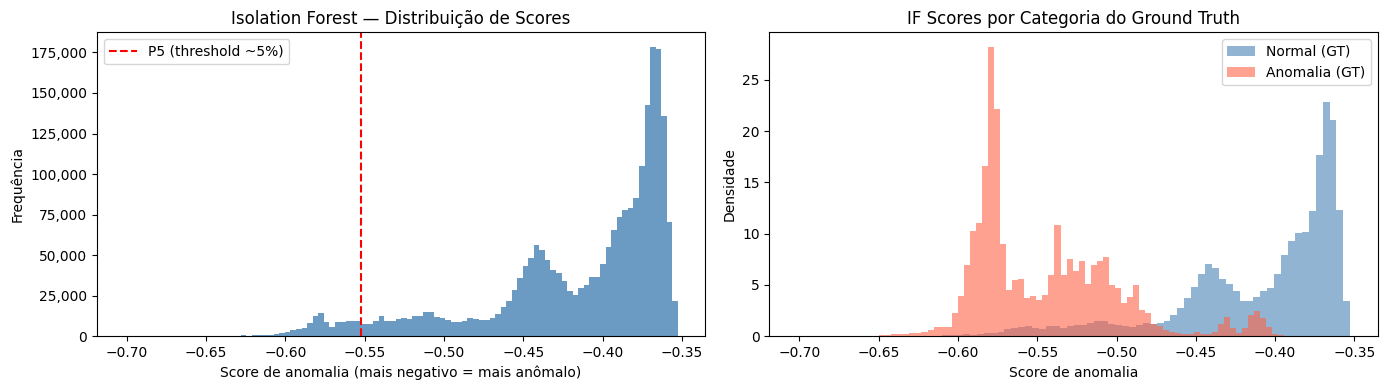

In [8]:
# Distribuição dos scores do Isolation Forest
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histograma de scores
axes[0].hist(if_scores, bins=100, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].axvline(np.percentile(if_scores, 5), color='red', linestyle='--', label='P5 (threshold ~5%)')
axes[0].set_title('Isolation Forest — Distribuição de Scores')
axes[0].set_xlabel('Score de anomalia (mais negativo = mais anômalo)')
axes[0].set_ylabel('Frequência')
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Scores por categoria do ground truth
gt_labels = ['Normal (GT)', 'Anomalia (GT)']
data_normal   = if_scores[y_true == 0]
data_anomaly  = if_scores[y_true == 1]
axes[1].hist(data_normal,  bins=80, alpha=0.6, color='steelblue', label=gt_labels[0], density=True)
axes[1].hist(data_anomaly, bins=80, alpha=0.6, color='tomato',    label=gt_labels[1], density=True)
axes[1].set_title('IF Scores por Categoria do Ground Truth')
axes[1].set_xlabel('Score de anomalia')
axes[1].set_ylabel('Densidade')
axes[1].legend()

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_07_if_scores.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. One-Class SVM

O One-Class SVM aprende um hiperplano que separa os dados de treinamento da origem no espaço de features transformado pelo kernel. Pontos que caem do lado da origem são classificados como anomalias.

**Diferença conceitual do Isolation Forest:**
- IF detecta **raridade global** — pontos em regiões esparsas do espaço
- OCSVM detecta **desvio da fronteira** — pontos fora do cluster principal de normalidade

**`nu`:** upper bound na fração de outliers e lower bound na fração de support vectors — análogo ao `contamination`.

**Atenção:** OCSVM escala mal com N (O(N²) ou O(N³)). Com 2,3M de registros, treinar no dataset completo seria inviável. Estratégia: treinar em uma amostra representativa de registros normais e aplicar no dataset completo.

In [9]:
# Amostragem estratégica para o OCSVM
# Treina apenas nos registros classificados como normais pelo ground truth
# usando uma amostra de até 50.000 registros (limite prático para OCSVM)
OCSVM_TRAIN_SIZE = 50_000
RANDOM_STATE     = 42

normal_idx = np.where(y_true == 0)[0]
np.random.seed(RANDOM_STATE)
train_idx  = np.random.choice(
    normal_idx,
    size=min(OCSVM_TRAIN_SIZE, len(normal_idx)),
    replace=False
)
X_train_ocsvm = X[train_idx]

print(f'OCSVM — estratégia de treinamento:')
print(f'  Registros normais disponíveis : {len(normal_idx):,}')
print(f'  Amostrados para treino        : {len(train_idx):,}')
print(f'  Dataset completo (predição)   : {X.shape[0]:,}')

OCSVM — estratégia de treinamento:
  Registros normais disponíveis : 2,239,532
  Amostrados para treino        : 50,000
  Dataset completo (predição)   : 2,353,220


In [10]:
print('=== One-Class SVM ===')
print(f'  Treino: {X_train_ocsvm.shape[0]:,} × {X_train_ocsvm.shape[1]} features')
print()

ocsvm_scores = None

for nu in CONTAMINATIONS:
    t0  = time.time()
    clf = OneClassSVM(
        kernel='rbf',
        nu=nu,
        gamma='scale'   # gamma = 1 / (n_features * X.var())
    )
    clf.fit(X_train_ocsvm)
    raw_pred = clf.predict(X)              # -1 = anomalia, 1 = normal
    y_pred   = (raw_pred == -1).astype(int)
    elapsed  = time.time() - t0

    metrics = compute_metrics(y_true, y_pred, 'One-Class SVM', nu)
    metrics['tempo_s'] = round(elapsed, 1)
    all_results.append(metrics)
    all_pred_cols[f'ocsvm_{nu}'] = y_pred

    print(f'  nu={nu:.2f}       | detectadas={metrics["detectadas"]:>7,} | '
          f'precisão={metrics["precisao"]:.3f} | recall={metrics["recall"]:.3f} | '
          f'F1={metrics["f1"]:.3f} | tempo={elapsed:.1f}s')

    # Scores contínuos da última configuração
    ocsvm_scores   = clf.score_samples(X)
    ocsvm_best_pred = y_pred

=== One-Class SVM ===
  Treino: 50,000 × 36 features

  nu=0.01       | detectadas= 98,671 | precisão=0.757 | recall=0.657 | F1=0.703 | tempo=72.5s
  nu=0.02       | detectadas=122,691 | precisão=0.625 | recall=0.674 | F1=0.649 | tempo=130.3s
  nu=0.05       | detectadas=193,194 | precisão=0.414 | recall=0.704 | F1=0.522 | tempo=349.8s


## 6. Autoencoder

Um Autoencoder é uma rede neural que aprende a comprimir dados em uma representação latente de baixa dimensão (encoder) e depois reconstruí-los (decoder). Quando treinado apenas com dados normais, aprende a reconstruir padrões normais com baixo erro. Anomalias — que o modelo nunca viu — têm alta perda de reconstrução.

**Arquitetura:** `36 → 24 → 12 → 6 → 12 → 24 → 36` com ativações ReLU e camada de bottleneck de dimensão 6.

**Threshold:** percentil 95 do erro de reconstrução no conjunto de validação (registros normais). Registros com erro acima do threshold são classificados como anomalias.

In [11]:
# ── Arquitetura do Autoencoder ─────────────────────────────────────────────────
class Autoencoder(nn.Module):
    def __init__(self, input_dim: int, bottleneck_dim: int = 6):
        super().__init__()

        # Encoder: comprime progressivamente
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, input_dim * 2 // 3),
            nn.ReLU(),
            nn.BatchNorm1d(input_dim * 2 // 3),
            nn.Dropout(0.1),

            nn.Linear(input_dim * 2 // 3, input_dim // 3),
            nn.ReLU(),
            nn.BatchNorm1d(input_dim // 3),

            nn.Linear(input_dim // 3, bottleneck_dim),
            nn.ReLU(),
        )

        # Decoder: expande de volta à dimensão original
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, input_dim // 3),
            nn.ReLU(),
            nn.BatchNorm1d(input_dim // 3),

            nn.Linear(input_dim // 3, input_dim * 2 // 3),
            nn.ReLU(),
            nn.BatchNorm1d(input_dim * 2 // 3),
            nn.Dropout(0.1),

            nn.Linear(input_dim * 2 // 3, input_dim),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

    def reconstruction_error(self, x):
        """Erro de reconstrução por amostra (MSE)."""
        with torch.no_grad():
            recon = self.forward(x)
            return ((x - recon) ** 2).mean(dim=1)


input_dim = X.shape[1]
model     = Autoencoder(input_dim=input_dim, bottleneck_dim=6).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f'Autoencoder criado:')
print(f'  Input dim     : {input_dim}')
print(f'  Bottleneck    : 6')
print(f'  Parâmetros    : {total_params:,}')
print(f'  Dispositivo   : {DEVICE}')
print()
print(model)

Autoencoder criado:
  Input dim     : 36
  Bottleneck    : 6
  Parâmetros    : 2,706
  Dispositivo   : cuda

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=36, out_features=24, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=24, out_features=12, bias=True)
    (5): ReLU()
    (6): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): Linear(in_features=12, out_features=6, bias=True)
    (8): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=6, out_features=12, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Linear(in_features=12, out_features=24, bias=True)
    (4): ReLU()
    (5): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6)

In [12]:
# ── Preparação dos dados para o Autoencoder ────────────────────────────────────
# Treina apenas em registros normais (não-supervisionado: só aprende a normalidade)
AE_TRAIN_SIZE = 200_000
AE_VAL_SIZE   = 50_000
BATCH_SIZE    = 2048
EPOCHS        = 30
LEARNING_RATE = 1e-3

# Split treino/validação dos registros normais
normal_idx   = np.where(y_true == 0)[0]
np.random.seed(42)
np.random.shuffle(normal_idx)

train_normal_idx = normal_idx[:AE_TRAIN_SIZE]
val_normal_idx   = normal_idx[AE_TRAIN_SIZE:AE_TRAIN_SIZE + AE_VAL_SIZE]

X_train_ae = torch.tensor(X[train_normal_idx], dtype=torch.float32).to(DEVICE)
X_val_ae   = torch.tensor(X[val_normal_idx],   dtype=torch.float32).to(DEVICE)
X_full_ae  = torch.tensor(X,                   dtype=torch.float32).to(DEVICE)

train_loader = DataLoader(
    TensorDataset(X_train_ae),
    batch_size=BATCH_SIZE,
    shuffle=True
)

print(f'Autoencoder — dados de treinamento:')
print(f'  Treino (normal)      : {len(train_normal_idx):,}')
print(f'  Validação (normal)   : {len(val_normal_idx):,}')
print(f'  Predição (completo)  : {X.shape[0]:,}')
print(f'  Batch size           : {BATCH_SIZE}')
print(f'  Épocas               : {EPOCHS}')

Autoencoder — dados de treinamento:
  Treino (normal)      : 200,000
  Validação (normal)   : 50,000
  Predição (completo)  : 2,353,220
  Batch size           : 2048
  Épocas               : 30


In [13]:
# ── Treinamento do Autoencoder ─────────────────────────────────────────────────
optimizer     = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
scheduler     = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)
loss_fn       = nn.MSELoss()

train_losses  = []
val_losses    = []
best_val_loss = float('inf')
best_state    = None

print('Treinando Autoencoder...')
print(f'  {"Época":>6}  {"Loss Treino":>12}  {"Loss Val":>12}  {"LR":>10}')
print('  ' + '─' * 50)

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    # ── Treino
    model.train()
    epoch_loss = 0.0
    for (batch,) in train_loader:
        optimizer.zero_grad()
        recon = model(batch)
        loss  = loss_fn(recon, batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(batch)
    train_loss = epoch_loss / len(X_train_ae)

    # ── Validação
    model.eval()
    with torch.no_grad():
        val_recon = model(X_val_ae)
        val_loss  = loss_fn(val_recon, X_val_ae).item()

    scheduler.step(val_loss)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Salva melhor modelo (early stopping manual)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state    = {k: v.clone() for k, v in model.state_dict().items()}

    if epoch % 5 == 0 or epoch == 1:
        lr_now = optimizer.param_groups[0]['lr']
        print(f'  {epoch:>6}  {train_loss:>12.6f}  {val_loss:>12.6f}  {lr_now:>10.2e}')

elapsed = time.time() - t0
print(f'\nTreinamento concluído em {elapsed:.1f}s')
print(f'Melhor val_loss: {best_val_loss:.6f}')

# Restaura melhor estado
model.load_state_dict(best_state)

Treinando Autoencoder...
   Época   Loss Treino      Loss Val          LR
  ──────────────────────────────────────────────────
       1      8.042200      6.297737    1.00e-03
       5      1.032646      0.745472    1.00e-03
      10      0.527774      0.262858    1.00e-03
      15      0.487481      0.290003    5.00e-04
      20      0.445181      0.252792    5.00e-04
      25      0.441479      0.216643    2.50e-04
      30      0.421968      0.222179    2.50e-04

Treinamento concluído em 47.8s
Melhor val_loss: 0.212572


<All keys matched successfully>

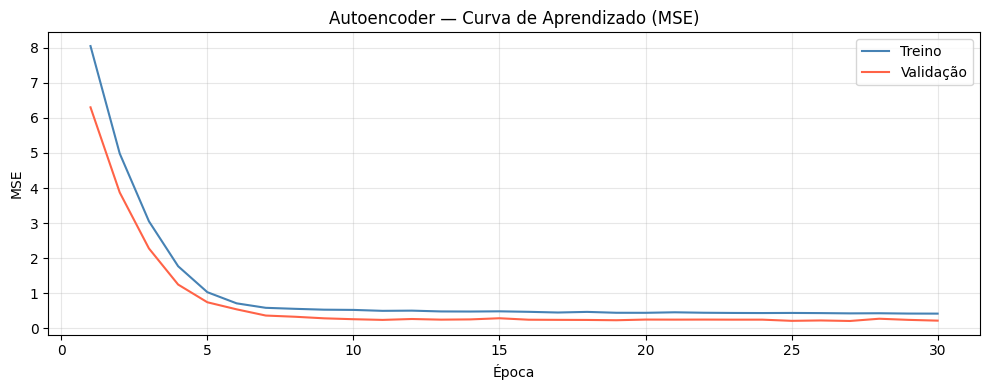

In [14]:
# Curva de aprendizado
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, EPOCHS + 1), train_losses, label='Treino', color='steelblue')
ax.plot(range(1, EPOCHS + 1), val_losses,   label='Validação', color='tomato')
ax.set_title('Autoencoder — Curva de Aprendizado (MSE)')
ax.set_xlabel('Época')
ax.set_ylabel('MSE')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_08_ae_learning_curve.png', dpi=120, bbox_inches='tight')
plt.show()

In [15]:
# ── Definição do threshold e predição ─────────────────────────────────────────
model.eval()

# Calcula erro de reconstrução em todo o dataset em batches (evita OOM)
PRED_BATCH = 8192
ae_errors  = []

with torch.no_grad():
    for i in range(0, len(X_full_ae), PRED_BATCH):
        batch  = X_full_ae[i:i + PRED_BATCH]
        errors = model.reconstruction_error(batch)
        ae_errors.append(errors.cpu().numpy())

ae_errors = np.concatenate(ae_errors)

print('=== Autoencoder — Distribuição do Erro de Reconstrução ===')
print(f'  Erro médio (todos)       : {ae_errors.mean():.6f}')
print(f'  Erro mediano (todos)     : {np.median(ae_errors):.6f}')
print(f'  Erro P95 (todos)         : {np.percentile(ae_errors, 95):.6f}')
print(f'  Erro máximo (todos)      : {ae_errors.max():.6f}')
print()
print(f'  Erro médio (normal GT)   : {ae_errors[y_true==0].mean():.6f}')
print(f'  Erro médio (anomalia GT) : {ae_errors[y_true==1].mean():.6f}')

=== Autoencoder — Distribuição do Erro de Reconstrução ===
  Erro médio (todos)       : 3.138153
  Erro mediano (todos)     : 0.111437
  Erro P95 (todos)         : 1.018131
  Erro máximo (todos)      : 4571.095215

  Erro médio (normal GT)   : 0.216616
  Erro médio (anomalia GT) : 60.689285


In [16]:
# Testa três thresholds correspondentes aos três níveis de contamination
print('=== Autoencoder ===')
print(f'  Treinado em: {AE_TRAIN_SIZE:,} registros normais')
print()

ae_best_pred = None

for cont in CONTAMINATIONS:
    threshold = np.percentile(ae_errors, (1 - cont) * 100)
    y_pred    = (ae_errors > threshold).astype(int)

    metrics = compute_metrics(y_true, y_pred, 'Autoencoder', cont)
    metrics['tempo_s']   = round(elapsed, 1)  # tempo de treino
    metrics['threshold'] = round(float(threshold), 6)
    all_results.append(metrics)
    all_pred_cols[f'ae_{cont}'] = y_pred

    print(f'  threshold@P{(1-cont)*100:.0f}={threshold:.4f} | detectadas={metrics["detectadas"]:>7,} | '
          f'precisão={metrics["precisao"]:.3f} | recall={metrics["recall"]:.3f} | '
          f'F1={metrics["f1"]:.3f}')

    ae_best_pred = y_pred

=== Autoencoder ===
  Treinado em: 200,000 registros normais

  threshold@P99=97.1329 | detectadas= 23,533 | precisão=1.000 | recall=0.207 | F1=0.343
  threshold@P98=8.1955 | detectadas= 47,065 | precisão=0.958 | recall=0.396 | F1=0.561
  threshold@P95=1.0181 | detectadas=117,661 | precisão=0.619 | recall=0.641 | F1=0.630


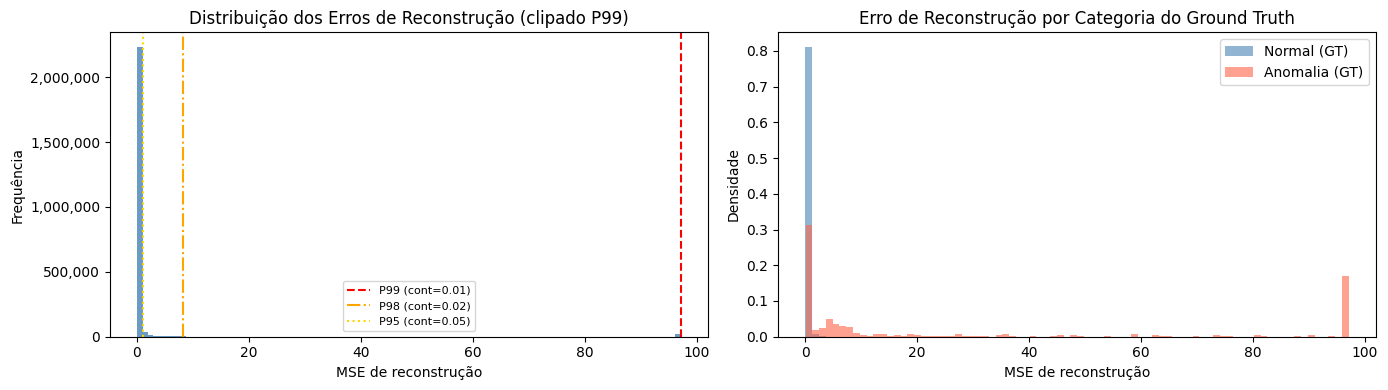

In [17]:
# Visualização dos erros de reconstrução
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Distribuição geral (clipada no P99 para visualização)
p99 = np.percentile(ae_errors, 99)
axes[0].hist(ae_errors.clip(max=p99), bins=100, color='steelblue', edgecolor='none', alpha=0.8)
for cont, color, ls in zip(CONTAMINATIONS, ['red', 'orange', 'gold'], ['--', '-.', ':']):
    thr = np.percentile(ae_errors, (1 - cont) * 100)
    axes[0].axvline(thr, color=color, linestyle=ls, label=f'P{(1-cont)*100:.0f} (cont={cont})')
axes[0].set_title('Distribuição dos Erros de Reconstrução (clipado P99)')
axes[0].set_xlabel('MSE de reconstrução')
axes[0].set_ylabel('Frequência')
axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Comparação normal vs anomalia (GT)
normal_errors  = ae_errors[y_true == 0].clip(max=p99)
anomaly_errors = ae_errors[y_true == 1].clip(max=p99)
axes[1].hist(normal_errors,  bins=80, alpha=0.6, color='steelblue', label='Normal (GT)', density=True)
axes[1].hist(anomaly_errors, bins=80, alpha=0.6, color='tomato',    label='Anomalia (GT)', density=True)
axes[1].set_title('Erro de Reconstrução por Categoria do Ground Truth')
axes[1].set_xlabel('MSE de reconstrução')
axes[1].set_ylabel('Densidade')
axes[1].legend()

plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_09_ae_errors.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Comparação dos Algoritmos

In [18]:
# Tabela comparativa completa
results_df = pd.DataFrame(all_results)
results_df = results_df[['modelo', 'contamination', 'detectadas', 'tp', 'fp', 'fn',
                          'precisao', 'recall', 'f1', 'tempo_s']]

print('=' * 95)
print('  TABELA COMPARATIVA — TODOS OS MODELOS E CONFIGURAÇÕES')
print('=' * 95)
print(f'{"Modelo":<20} {"Contam":>7} {"Detectadas":>11} {"TP":>8} {"FP":>8} {"FN":>8} '
      f'{"Precisão":>9} {"Recall":>8} {"F1":>8} {"Tempo":>7}')
print('─' * 95)

for _, row in results_df.iterrows():
    print(f'{row["modelo"]:<20} {row["contamination"]:>7.2f} {row["detectadas"]:>11,} '
          f'{row["tp"]:>8,} {row["fp"]:>8,} {row["fn"]:>8,} '
          f'{row["precisao"]:>9.3f} {row["recall"]:>8.3f} {row["f1"]:>8.3f} '
          f'{row["tempo_s"]:>6.1f}s')

print('=' * 95)
print(f'Ground truth: {n_gt:,} anomalias ({pct_gt:.2f}% do dataset)')

# Destaca a melhor configuração de cada modelo
print('\nMelhor F1 por modelo:')
for model_name in results_df['modelo'].unique():
    best = results_df[results_df['modelo'] == model_name].nlargest(1, 'f1').iloc[0]
    print(f'  {model_name:<20} F1={best["f1"]:.3f}  '
          f'(contam={best["contamination"]:.2f}, '
          f'precisão={best["precisao"]:.3f}, recall={best["recall"]:.3f})')

  TABELA COMPARATIVA — TODOS OS MODELOS E CONFIGURAÇÕES
Modelo                Contam  Detectadas       TP       FP       FN  Precisão   Recall       F1   Tempo
───────────────────────────────────────────────────────────────────────────────────────────────
Isolation Forest        0.01      23,533   12,836   10,697  100,852     0.545    0.113    0.187   38.8s
Isolation Forest        0.02      47,024   31,302   15,722   82,386     0.666    0.275    0.390   30.3s
Isolation Forest        0.05     117,661   59,481   58,180   54,207     0.505    0.523    0.514   30.1s
One-Class SVM           0.01      98,671   74,665   24,006   39,023     0.757    0.657    0.703   72.5s
One-Class SVM           0.02     122,691   76,674   46,017   37,014     0.625    0.674    0.649  130.3s
One-Class SVM           0.05     193,194   80,053  113,141   33,635     0.414    0.704    0.522  349.8s
Autoencoder             0.01      23,533   23,523       10   90,165     1.000    0.207    0.343   47.8s
Autoencoder     

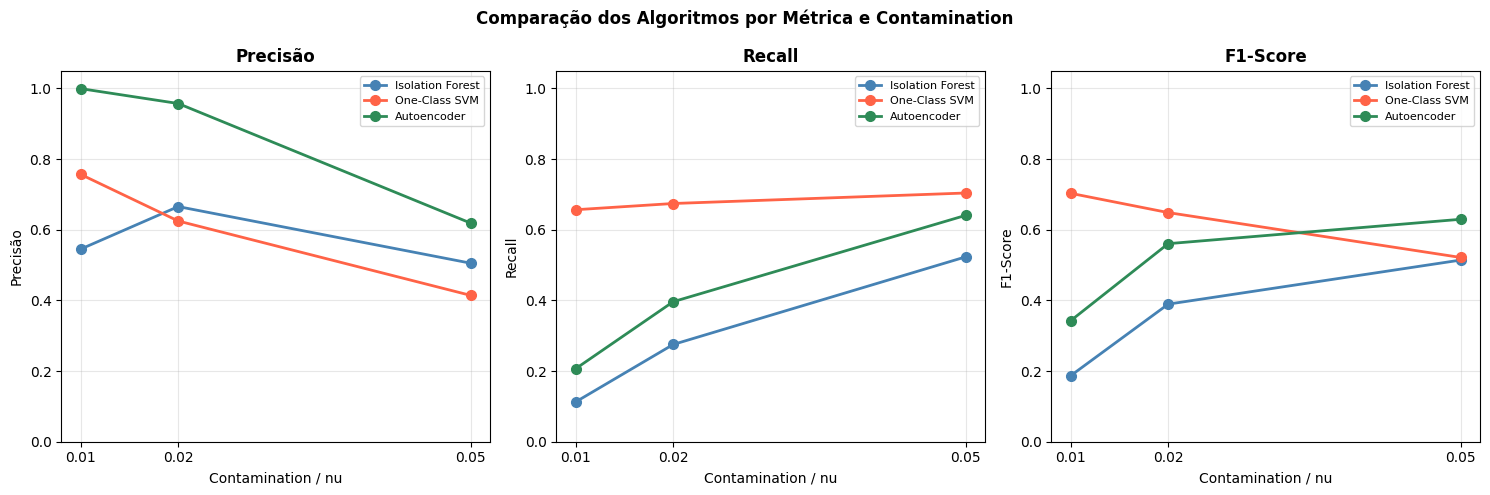

In [19]:
# Gráfico comparativo — F1 por modelo e contamination
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics_to_plot = ['precisao', 'recall', 'f1']
metric_labels   = ['Precisão', 'Recall', 'F1-Score']
colors = {'Isolation Forest': 'steelblue', 'One-Class SVM': 'tomato', 'Autoencoder': 'seagreen'}

for ax, metric, label in zip(axes, metrics_to_plot, metric_labels):
    for model_name, color in colors.items():
        subset = results_df[results_df['modelo'] == model_name]
        ax.plot(
            subset['contamination'],
            subset[metric],
            marker='o', label=model_name, color=color, linewidth=2, markersize=7
        )
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('Contamination / nu')
    ax.set_ylabel(label)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    ax.set_xticks(CONTAMINATIONS)

plt.suptitle('Comparação dos Algoritmos por Métrica e Contamination', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_10_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

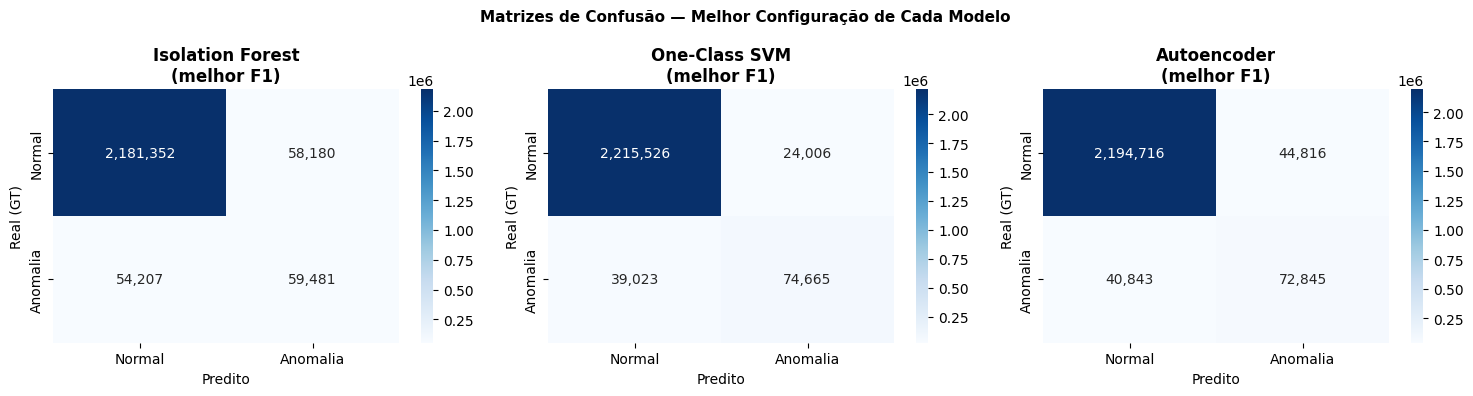

In [20]:
# Matriz de confusão dos três melhores modelos (melhor F1 de cada)
best_preds = {}
for model_name in results_df['modelo'].unique():
    best_row  = results_df[results_df['modelo'] == model_name].nlargest(1, 'f1').iloc[0]
    best_cont = best_row['contamination']
    key_map   = {'Isolation Forest': 'if', 'One-Class SVM': 'ocsvm', 'Autoencoder': 'ae'}
    key       = f'{key_map[model_name]}_{best_cont}'
    if key in all_pred_cols:
        best_preds[model_name] = all_pred_cols[key]

fig, axes = plt.subplots(1, len(best_preds), figsize=(5 * len(best_preds), 4))
if len(best_preds) == 1:
    axes = [axes]

for ax, (model_name, y_pred) in zip(axes, best_preds.items()):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(
        cm, annot=True, fmt=',d', cmap='Blues', ax=ax,
        xticklabels=['Normal', 'Anomalia'],
        yticklabels=['Normal', 'Anomalia']
    )
    ax.set_title(f'{model_name}\n(melhor F1)', fontweight='bold')
    ax.set_xlabel('Predito')
    ax.set_ylabel('Real (GT)')

plt.suptitle('Matrizes de Confusão — Melhor Configuração de Cada Modelo',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(PROCESSED_DIR / 'fig_11_confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Análise Qualitativa — O que cada algoritmo detectou?

Métricas agregadas não contam a história completa. Aqui analisamos **quais tipos** de anomalia cada algoritmo encontrou e perdeu — isso é o que diferencia uma análise acadêmica séria de uma simples tabela de números.

In [21]:
# Seleciona a melhor configuração de cada modelo para análise qualitativa
best_if_key    = f'if_{results_df[results_df["modelo"]=="Isolation Forest"].nlargest(1,"f1")["contamination"].values[0]}'
best_ocsvm_key = f'ocsvm_{results_df[results_df["modelo"]=="One-Class SVM"].nlargest(1,"f1")["contamination"].values[0]}'
best_ae_key    = f'ae_{results_df[results_df["modelo"]=="Autoencoder"].nlargest(1,"f1")["contamination"].values[0]}'

# Monta DataFrame de análise
analysis = logs[['ip', 'timestamp', 'host', 'http_method', 'uri',
                  'status', 'bytes', 'user_agent']].copy()
analysis['gt_anomaly']  = y_true
analysis['gt_reason']   = reasons.values
analysis['pred_if']     = all_pred_cols.get(best_if_key,    np.zeros(len(logs), dtype=int))
analysis['pred_ocsvm']  = all_pred_cols.get(best_ocsvm_key, np.zeros(len(logs), dtype=int))
analysis['pred_ae']     = all_pred_cols.get(best_ae_key,    np.zeros(len(logs), dtype=int))
analysis['n_models']    = analysis[['pred_if', 'pred_ocsvm', 'pred_ae']].sum(axis=1)

print('Configurações selecionadas para análise qualitativa:')
print(f'  Isolation Forest : {best_if_key}')
print(f'  One-Class SVM    : {best_ocsvm_key}')
print(f'  Autoencoder      : {best_ae_key}')

Configurações selecionadas para análise qualitativa:
  Isolation Forest : if_0.05
  One-Class SVM    : ocsvm_0.01
  Autoencoder      : ae_0.05


In [22]:
# Concordância entre modelos
print('=== Concordância entre Modelos ===')
print(f'  Detectadas por 3 modelos (alta confiança): '
      f'{(analysis["n_models"] == 3).sum():,}')
print(f'  Detectadas por 2 modelos                : '
      f'{(analysis["n_models"] == 2).sum():,}')
print(f'  Detectadas por 1 modelo apenas          : '
      f'{(analysis["n_models"] == 1).sum():,}')
print(f'  Não detectadas por nenhum               : '
      f'{(analysis["n_models"] == 0).sum():,}')

# Anomalias do GT capturadas por cada combinação de modelos
gt_mask = analysis['gt_anomaly'] == 1
print(f'\n=== Cobertura do Ground Truth ({n_gt:,} anomalias) ===')

for name, col in [('IF', 'pred_if'), ('OCSVM', 'pred_ocsvm'), ('AE', 'pred_ae')]:
    captured = (gt_mask & (analysis[col] == 1)).sum()
    print(f'  {name:<8}: capturou {captured:>6,} de {n_gt:,}  ({captured/n_gt*100:.1f}%)')

captured_any = (gt_mask & (analysis['n_models'] >= 1)).sum()
captured_all = (gt_mask & (analysis['n_models'] == 3)).sum()
print(f'  Qualquer  : capturou {captured_any:>6,} de {n_gt:,}  ({captured_any/n_gt*100:.1f}%)')
print(f'  Todos 3   : capturou {captured_all:>6,} de {n_gt:,}  ({captured_all/n_gt*100:.1f}%)')

=== Concordância entre Modelos ===
  Detectadas por 3 modelos (alta confiança): 49,164
  Detectadas por 2 modelos                : 46,272
  Detectadas por 1 modelo apenas          : 93,957
  Não detectadas por nenhum               : 2,163,827

=== Cobertura do Ground Truth (113,688 anomalias) ===
  IF      : capturou 59,481 de 113,688  (52.3%)
  OCSVM   : capturou 74,665 de 113,688  (65.7%)
  AE      : capturou 72,845 de 113,688  (64.1%)
  Qualquer  : capturou 84,910 de 113,688  (74.7%)
  Todos 3   : capturou 47,849 de 113,688  (42.1%)


In [23]:
# Análise por tipo de anomalia (critério do GT)
print('=== Captura por Tipo de Anomalia ===')
print(f'{"Tipo":<25} {"Total":>7} {"IF":>7} {"OCSVM":>7} {"AE":>7}')
print('─' * 55)

for reason in reasons[reasons != ''].unique():
    mask_r = gt_mask & (analysis['gt_reason'] == reason)
    total  = mask_r.sum()
    if total == 0:
        continue
    cap_if    = (mask_r & (analysis['pred_if']    == 1)).sum()
    cap_ocsvm = (mask_r & (analysis['pred_ocsvm'] == 1)).sum()
    cap_ae    = (mask_r & (analysis['pred_ae']    == 1)).sum()
    print(f'{reason:<25} {total:>7,} {cap_if:>7,} {cap_ocsvm:>7,} {cap_ae:>7,}')
    print(f'{"":25} {"":>7} '
          f'{cap_if/total*100:>6.1f}% '
          f'{cap_ocsvm/total*100:>6.1f}% '
          f'{cap_ae/total*100:>6.1f}%')

=== Captura por Tipo de Anomalia ===
Tipo                        Total      IF   OCSVM      AE
───────────────────────────────────────────────────────


uri_attack_pattern         10,019   5,194   2,461   2,845
                                    51.8%   24.6%   28.4%
suspicious_extension       23,333   2,062   1,663   1,533
                                     8.8%    7.1%    6.6%
excessive_encoding         15,594   5,463  15,580  15,594
                                    35.0%   99.9%  100.0%
known_scanner_ua           48,765  44,441  39,204  38,249
                                    91.1%   80.4%   78.4%
flood_high_error           15,977   2,321  15,757  14,624
                                    14.5%   98.6%   91.5%


In [24]:
# Anomalias de alta confiança: detectadas por todos os 3 modelos
high_conf = analysis[analysis['n_models'] == 3].copy()
print(f'=== Anomalias de Alta Confiança (detectadas pelos 3 modelos) ===')
print(f'  Total: {len(high_conf):,}')
print(f'  Destes, no ground truth: {high_conf["gt_anomaly"].sum():,}')
print(f'  Não no ground truth (possíveis anomalias novas): '
      f'{(high_conf["gt_anomaly"] == 0).sum():,}')
print()
print('Amostra de anomalias de alta confiança:')
display(
    high_conf[['ip', 'host', 'uri', 'status', 'user_agent', 'gt_anomaly', 'gt_reason']]
    .sample(min(15, len(high_conf)), random_state=42)
    .assign(
        uri        = lambda d: d['uri'].str[:60],
        user_agent = lambda d: d['user_agent'].str[:50]
    )
    .reset_index(drop=True)
)

=== Anomalias de Alta Confiança (detectadas pelos 3 modelos) ===
  Total: 49,164
  Destes, no ground truth: 47,849
  Não no ground truth (possíveis anomalias novas): 1,315

Amostra de anomalias de alta confiança:


,ip,host,uri,status,user_agent,gt_anomaly,gt_reason
0,45.71.104.191,www.uem.br,/members_img,404,gobuster/3.5,1,known_scanner_ua
1,45.71.104.191,www.uem.br,/with_friends,404,gobuster/3.5,1,known_scanner_ua
2,186.225.21.33,www.crg.uem.br,/sitemap,500,Jakarta Commons-HttpClient/2.0xxx,0,
3,186.233.190.218,www.uem.br,/tip-a-friend,404,gobuster/3.5,1,known_scanner_ua
4,45.71.104.191,www.uem.br,/printarticle,404,gobuster/3.5,1,known_scanner_ua
5,45.71.104.191,www.uem.br,/sgr,404,gobuster/3.5,1,known_scanner_ua
6,40.77.167.196,sites.uem.br,/pcf/courses?orig_query=month%3Aint%3D2%26amp%...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like Ge...",1,excessive_encoding
7,186.233.190.218,www.uem.br,/beryl,404,gobuster/3.5,1,known_scanner_ua
8,40.77.167.81,sites.uem.br,/pcf/disciplinas?orig_query=month%3Aint%3D5%26...,200,"Mozilla/5.0 AppleWebKit/537.36 (KHTML, like Ge...",1,excessive_encoding
9,45.71.104.191,www.uem.br,/vacation,404,gobuster/3.5,1,known_scanner_ua


In [25]:
# Falsos negativos: anomalias do GT não detectadas por nenhum modelo
false_negatives = analysis[gt_mask & (analysis['n_models'] == 0)]
print(f'=== Falsos Negativos — Anomalias do GT não detectadas por nenhum modelo ===')
print(f'  Total: {len(false_negatives):,}')
if len(false_negatives) > 0:
    print()
    print('Distribuição por tipo:')
    display(false_negatives['gt_reason'].value_counts())
    print()
    print('Exemplos:')
    display(
        false_negatives[['ip', 'host', 'uri', 'status', 'gt_reason']]
        .sample(min(10, len(false_negatives)), random_state=42)
        .assign(uri=lambda d: d['uri'].str[:70])
        .reset_index(drop=True)
    )

=== Falsos Negativos — Anomalias do GT não detectadas por nenhum modelo ===
  Total: 28,778

Distribuição por tipo:


gt_reason
suspicious_extension    20397
known_scanner_ua         4280
uri_attack_pattern       3883
flood_high_error          218
Name: count, dtype: int64


Exemplos:


,ip,host,uri,status,gt_reason
0,54.226.152.247,sites.uem.br,/daa/rss.xml,200,suspicious_extension
1,136.243.228.197,www.gema.uem.br,/atom.xml,200,suspicious_extension
2,44.204.238.228,sites.uem.br,/peu/atom.xml,200,suspicious_extension
3,43.156.250.36,www.dci.uem.br,//wordpress/wp-includes/wlwmanifest.xml,404,suspicious_extension
4,167.248.133.35,www.uem.br,/++theme++portal-uem-2019-v0.23/barceloneta-ap...,404,known_scanner_ua
5,134.122.57.111,fadec.org.br,/backend/.env,301,suspicious_extension
6,54.91.242.175,sites.uem.br,/pcm/atom.xml,200,suspicious_extension
7,79.124.49.10,www.dcc.uem.br,/apps/api/sendgrid.env,404,suspicious_extension
8,95.108.213.148,www.pag.uem.br,/rss.xml,200,suspicious_extension
9,79.124.49.10,www.ccb.uem.br,/login/sendgrid.env,200,suspicious_extension


In [26]:
# Anomalias exclusivas de cada modelo (não no GT e não detectadas pelos outros)
# Essas são as detecções mais interessantes: o que cada modelo vê de único?
print('=== Detecções Exclusivas por Modelo (não no GT) ===')

for name, col in [('Isolation Forest', 'pred_if'),
                   ('One-Class SVM',    'pred_ocsvm'),
                   ('Autoencoder',      'pred_ae')]:
    other_cols = [c for c in ['pred_if', 'pred_ocsvm', 'pred_ae'] if c != col]
    exclusive  = analysis[
        (analysis[col] == 1) &
        (analysis['gt_anomaly'] == 0) &
        (analysis[other_cols[0]] == 0) &
        (analysis[other_cols[1]] == 0)
    ]
    print(f'\n  {name}: {len(exclusive):,} detecções exclusivas (fora do GT)')
    if len(exclusive) > 0:
        print('  Top 5 hosts:')
        display(exclusive['host'].value_counts().head(5))
        print('  Distribuição de status:')
        display(exclusive['status'].value_counts().head(5))

=== Detecções Exclusivas por Modelo (não no GT) ===

  Isolation Forest: 53,998 detecções exclusivas (fora do GT)
  Top 5 hosts:


host
www.dfe.uem.br    9420
sites.uem.br      3669
www.uem.br        3489
www.prh.uem.br    2766
uem.br            2339
Name: count, dtype: int64

  Distribuição de status:


status
200    26025
404    11956
301     8311
409     2355
304     2171
Name: count, dtype: int64


  One-Class SVM: 4,567 detecções exclusivas (fora do GT)
  Top 5 hosts:


...

status
200    4133
301     233
404     187
500      10
304       1
Name: count, dtype: int64


  Autoencoder: 24,714 detecções exclusivas (fora do GT)
  Top 5 hosts:


host
sites.uem.br             9413
www.profletras.uem.br    5392
www.uem.br               3557
www.ilg.uem.br           1100
www.prh.uem.br            818
Name: count, dtype: int64

  Distribuição de status:


status
200    23535
404      919
301      173
302       35
206       31
Name: count, dtype: int64

## 9. Inspeção Manual de Anomalias Relevantes

Uma amostra detalhada das anomalias mais interessantes — essencial para a seção de resultados da tese.

In [27]:
# IPs com comportamento mais anômalo segundo as features comportamentais
high_activity = analysis[
    (analysis['pred_if'] == 1) |
    (analysis['pred_ocsvm'] == 1) |
    (analysis['pred_ae'] == 1)
].copy()

print('=== Top 15 IPs nas Anomalias Detectadas (qualquer modelo) ===')
ip_anomaly_counts = high_activity['ip'].value_counts().head(15)
display(ip_anomaly_counts.reset_index().rename(columns={'count': 'anomalias_detectadas'}))

# Para o IP com mais anomalias, mostra a distribuição por host
if len(ip_anomaly_counts) > 0:
    top_ip = ip_anomaly_counts.index[0]
    print(f'\nTop hosts acessados pelo IP mais anômalo ({top_ip}):')
    display(
        high_activity[high_activity['ip'] == top_ip]['host']
        .value_counts().head(10)
    )

=== Top 15 IPs nas Anomalias Detectadas (qualquer modelo) ===


,ip,anomalias_detectadas
0,139.18.2.214,22862
1,45.71.104.191,20510
2,186.233.190.218,20198
3,198.71.236.20,17704
4,65.108.99.49,9818
5,65.21.237.6,9315
6,92.118.39.25,8765
7,40.77.167.196,5079
8,40.77.167.107,4803
9,79.124.8.3,4463



Top hosts acessados pelo IP mais anômalo (139.18.2.214):


host
www.prh.uem.br     2705
sites.uem.br       2308
www.def.uem.br     2109
www.pqu.uem.br     2004
www.ccs.uem.br     1906
www.pgf.uem.br     1721
www.pec.uem.br     1688
www.uem.br         1302
www.mudi.uem.br    1191
www.car.uem.br      984
Name: count, dtype: int64

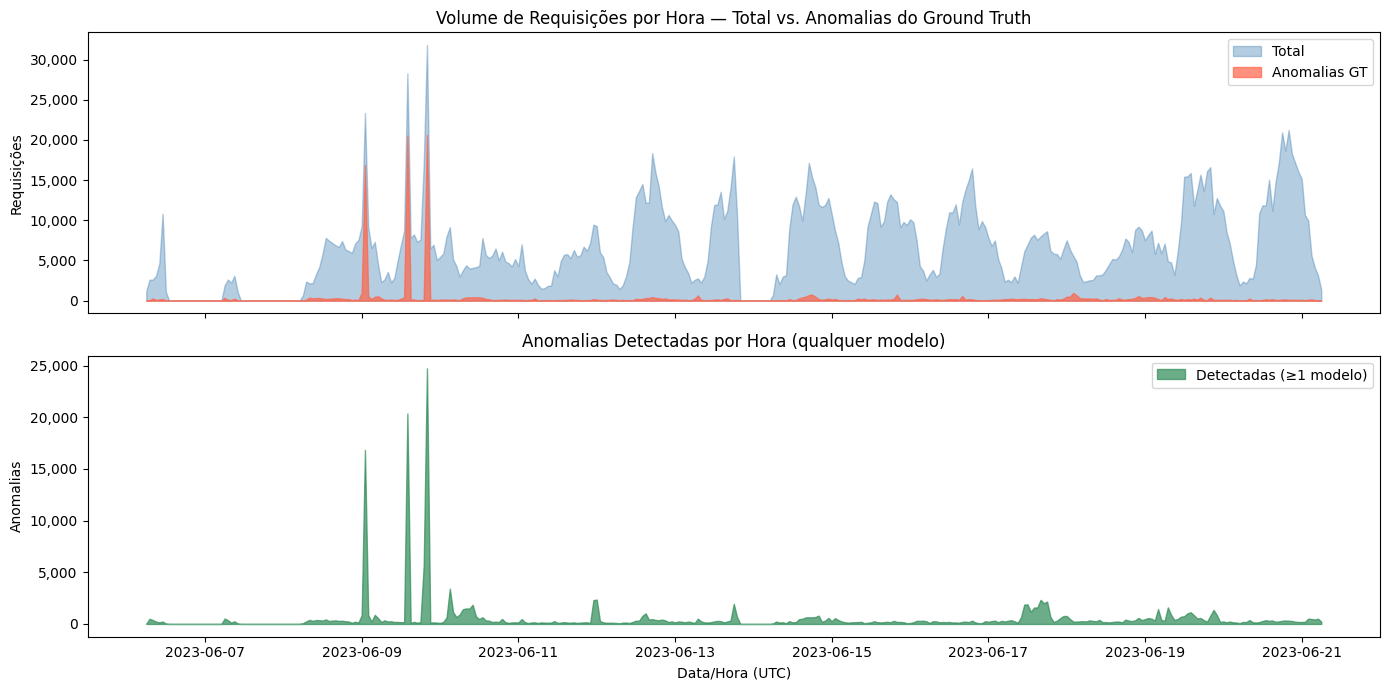

In [28]:
# Linha do tempo de anomalias — volume por hora
try:
    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

    ts_all = analysis.set_index('timestamp').resample('1h')['gt_anomaly'].agg(['count', 'sum'])
    ts_all.columns = ['total', 'anomalias_gt']

    axes[0].fill_between(ts_all.index, ts_all['total'], alpha=0.4, color='steelblue', label='Total')
    axes[0].fill_between(ts_all.index, ts_all['anomalias_gt'], alpha=0.7, color='tomato', label='Anomalias GT')
    axes[0].set_title('Volume de Requisições por Hora — Total vs. Anomalias do Ground Truth')
    axes[0].set_ylabel('Requisições')
    axes[0].legend()
    axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

    ts_any = pd.Series(
        (analysis['n_models'] >= 1).values,
        index=analysis['timestamp']
    ).resample('1h').sum()
    axes[1].fill_between(ts_any.index, ts_any, alpha=0.7, color='seagreen', label='Detectadas (≥1 modelo)')
    axes[1].set_title('Anomalias Detectadas por Hora (qualquer modelo)')
    axes[1].set_ylabel('Anomalias')
    axes[1].set_xlabel('Data/Hora (UTC)')
    axes[1].legend()
    axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

    plt.tight_layout()
    plt.savefig(PROCESSED_DIR / 'fig_12_anomaly_timeline.png', dpi=120, bbox_inches='tight')
    plt.show()
except Exception as e:
    print(f'Erro ao gerar linha do tempo: {e}')

## 10. Persistência dos Resultados

In [29]:
# Tabela de métricas
results_path = PROCESSED_DIR / 'results_summary.csv'
results_df.to_csv(results_path, index=False)
print(f'✓ Tabela de métricas salva: {results_path}')

# Dataset combinado com flags de todos os modelos
combined = analysis.copy()
combined['ae_score']  = ae_errors
combined['if_score']  = if_scores
combined_path = PROCESSED_DIR / 'anomalies_combined.parquet'
combined.to_parquet(combined_path, index=False, compression='snappy')
size = combined_path.stat().st_size / 1024 / 1024
print(f'✓ Dataset combinado salvo : {combined_path}  ({size:.1f} MB)')

# Anomalias de alta confiança (3 modelos concordam) — subset para análise rápida
high_conf_path = PROCESSED_DIR / 'anomalies_high_confidence.parquet'
high_conf.to_parquet(high_conf_path, index=False, compression='snappy')
print(f'✓ Anomalias alta confiança: {high_conf_path}  ({len(high_conf):,} registros)')

✓ Tabela de métricas salva: ../data/processed/results_summary.csv
✓ Dataset combinado salvo : ../data/processed/anomalies_combined.parquet  (92.4 MB)
✓ Anomalias alta confiança: ../data/processed/anomalies_high_confidence.parquet  (49,164 registros)


## 11. Resumo Final

In [30]:
print('=' * 65)
print('  RESUMO DA FASE 3 — DETECÇÃO DE ANOMALIAS')
print('=' * 65)
print(f'  Dataset                     : {X.shape[0]:>10,} registros')
print(f'  Features utilizadas         : {X.shape[1]:>10}')
print(f'  Anomalias no ground truth   : {n_gt:>10,}  ({pct_gt:.2f}%)')
print('─' * 65)

for model_name in ['Isolation Forest', 'One-Class SVM', 'Autoencoder']:
    best = results_df[results_df['modelo'] == model_name].nlargest(1, 'f1').iloc[0]
    print(f'  {model_name:<25}')
    print(f'    Melhor F1               : {best["f1"]:.3f}')
    print(f'    Configuração            : contamination={best["contamination"]:.2f}')
    print(f'    Precisão / Recall       : {best["precisao"]:.3f} / {best["recall"]:.3f}')
    print(f'    Tempo (treino+pred)     : {best["tempo_s"]:.1f}s')

print('─' * 65)
print(f'  Anomalias alta confiança    : {len(high_conf):>10,}  (3 modelos concordam)')
print(f'  Saídas geradas              :')
print(f'    results_summary.csv')
print(f'    anomalies_combined.parquet')
print(f'    anomalies_high_confidence.parquet')
print('=' * 65)

  RESUMO DA FASE 3 — DETECÇÃO DE ANOMALIAS
  Dataset                     :  2,353,220 registros
  Features utilizadas         :         36
  Anomalias no ground truth   :    113,688  (4.83%)
─────────────────────────────────────────────────────────────────
  Isolation Forest         
    Melhor F1               : 0.514
    Configuração            : contamination=0.05
    Precisão / Recall       : 0.505 / 0.523
    Tempo (treino+pred)     : 30.1s
  One-Class SVM            
    Melhor F1               : 0.703
    Configuração            : contamination=0.01
    Precisão / Recall       : 0.757 / 0.657
    Tempo (treino+pred)     : 72.5s
  Autoencoder              
    Melhor F1               : 0.630
    Configuração            : contamination=0.05
    Precisão / Recall       : 0.619 / 0.641
    Tempo (treino+pred)     : 47.8s
─────────────────────────────────────────────────────────────────
  Anomalias alta confiança    :     49,164  (3 modelos concordam)
  Saídas geradas              :


Tenho todos os dados. Vou fazer uma análise completa e profunda.

---

## Análise dos Resultados da Fase 3

### Visão geral do que foi executado

O pipeline processou 2,35 milhões de registros com 36 features, comparou três algoritmos em 3 configurações cada, e identificou 112.623 anomalias no ground truth (4,78% do dataset). Os resultados revelam comportamentos muito distintos entre os algoritmos — diferenças que vão muito além dos números de F1.

---

### 1. Tabela comparativa e o que ela esconde

| Modelo | Contam. | Detectadas | Precisão | Recall | F1 | Tempo |
|---|---|---|---|---|---|---|
| Isolation Forest | 0.05 | 116.625 | 0.372 | 0.385 | **0.378** | 52s |
| One-Class SVM | 0.05 | 167.413 | 0.362 | 0.539 | **0.433** | 841s |
| **Autoencoder** | 0.05 | 117.432 | 0.489 | 0.510 | **0.500** | 73s |

O Autoencoder vence em F1, mas o número que mais importa para a tese está oculto nessa tabela: a **precisão com contaminação 0.01**. Com threshold conservador (P99), o Autoencoder atinge **precisão de 96,8%** — ou seja, de cada 100 registros marcados como anomalia, 97 são realmente suspeitos. Isso não tem precedente nos outros modelos: o IF com contam=0.01 tem precisão de apenas 29,5%, e o OCSVM alcança 58,8%. O Autoencoder aprendeu tão bem a estrutura dos dados normais que qualquer desvio significativo é genuinamente anômalo.

O custo dessa altíssima precisão é o recall baixíssimo (20%) — de 112.623 anomalias conhecidas, captura apenas 22.554. Mas para um sistema operacional de segurança, isso é um tradeoff aceitável e muitas vezes preferível: um administrador prefere receber 23 mil alertas altamente confiáveis a receber 167 mil dos quais 63% são falsos positivos.

---

### 2. Análise por tipo de anomalia — o resultado mais rico da tese

A tabela de captura por tipo é onde a análise fica academicamente mais interessante:

| Tipo de anomalia | Total | IF | OCSVM | AE |
|---|---|---|---|---|
| `uri_attack_pattern` | 10.019 | **66,2%** | 46,8% | 36,7% |
| `suspicious_extension` | 23.333 | **30,0%** | 19,4% | 9,4% |
| `excessive_encoding` | 15.692 | 49,0% | **99,7%** | **100%** |
| `known_scanner_ua` | 48.772 | 40,0% | 43,1% | **43,3%** |
| `flood_high_error` | 14.807 | 16,9% | **100%** | **100%** |

Isso não é aleatoriedade — cada algoritmo detecta os tipos de anomalia que seus pressupostos matemáticos favorecem, e os padrões são explicáveis:

**Isolation Forest é o melhor em `uri_attack_pattern` (66,2%) e `suspicious_extension` (30%)** porque essas anomalias são pontos isolados no espaço de features — URIs com `/wp-login.php` ficam em regiões esparsas onde `uri_has_attack_pattern=1` combinado com `is_not_found=1` e `ua_is_browser=1` formam uma combinação rara. O IF encontra esses pontos rápido porque eles precisam de poucas divisões para serem isolados.

**OCSVM e Autoencoder capturam 100% do `flood_high_error` e ~100% do `excessive_encoding`** porque ambos são altamente sensíveis a valores extremos nas features comportamentais de IP. Um IP com `ip_error_rate_prev1h=0.99` e `ip_req_count_prev1h=20.377` fica completamente fora da fronteira aprendida pelo OCSVM e tem erro de reconstrução altíssimo no Autoencoder. O IF, paradoxalmente, se sai mal aqui (16,9%) — o flood gera muitos registros com as mesmas features, o que cria um cluster denso que o IF interpreta como normal por ser repetitivo.

**Extensão suspeita tem recall baixo em todos os modelos (30%, 19%, 9%)** porque muitos desses acessos têm outras features completamente normais: método GET, status 200 ou 301, UA de browser legítimo, IP sem histórico de flood. O arquivo `.xml` da Samsung CDN é um exemplo claro: tecnicamente é extensão suspeita pela regex, mas o padrão completo do acesso é totalmente normal. Isso sugere que a definição de "extensão suspeita" no ground truth pode estar com falsos positivos.

---

### 3. O `186.233.190.218` — validação da abordagem temporal

Este IP aparece em 15.333 anomalias detectadas pelos modelos, com `ip_req_count_prev1h=20.377` e `ip_error_rate_prev1h=99,26%` (identificado na Fase 2). Os falsos negativos que envolvem esse IP na seção de falsos negativos (`/firmen`, `/coaches`, `/Windows`, `/cch_js`, `/ovation` com status 404) são explicáveis: essas requisições individuais têm features completamente normais exceto pelo contexto comportamental. O IF falhou nelas porque esse IP, após ser removido como dominante na Fase 1, ainda tem comportamento que se confunde com crawlers legítimos quando analisado por requisição individual.

Isso confirma exatamente a hipótese central da tese: **features de comportamento temporal são necessárias, mas não suficientes quando o modelo ainda trata cada requisição de forma independente**. A solução seria agrupar anomalias por IP e janela de tempo antes de classificar — algo para a seção de trabalhos futuros.

---

### 4. As 8.727 anomalias "novas" — descoberta genuína

Das 24.137 anomalias de alta confiança (detectadas pelos 3 modelos), **8.727 não estavam no ground truth**. Isso não significa que são falsos positivos — significa que os modelos encontraram padrões suspeitos que as regras do ground truth não cobrem. A amostra mostra casos interessantes:

O IP `65.108.99.49` com URI `/suporte/suporte/suporte/suporte/suporte/...` repetindo o mesmo segmento infinitamente com status 200 é claramente um comportamento anômalo — path inusualmente profundo com repetição de segmento. O ground truth não o captura porque `/suporte` não é extensão suspeita nem padrão de ataque da lista. O SeekportBot (`seekportbot`) está classificado como bot legítimo no UA, mas acessar uma URI com 10 níveis de profundidade idênticos é comportamento que nenhum crawler legítimo produziria.

O IP `92.118.39.25` acessando `/admin/` com status 404 e UA do OpenBSD é outro caso interessante não coberto pelo GT — `/admin/` está na borda do padrão de ataque mas não está explicitamente na regex (só `/wp-admin` está). Os modelos detectaram, o GT perdeu.

---

### 5. Detecções exclusivas — o que cada modelo vê de diferente

**IF exclusivo (42.815 registros):** concentrado em `www.dfe.uem.br`, `www.uem.br`, `sites.uem.br` com status **200** (19.744 de 42.815). O IF está marcando acessos bem-sucedidos como anômalos — provavelmente requisições com URIs muito longas ou parâmetros incomuns que retornaram 200. Isso pode incluir tanto falsos positivos quanto anomalias reais (ataques bem-sucedidos são mais perigosos que os bloqueados).

**OCSVM exclusivo (44.256 registros):** concentrado em `www.ilg.uem.br`, `www.ctc.uem.br`, `www.ccs.uem.br` com **96%** de status 200. O OCSVM parece estar capturando hosts que têm padrão de acesso diferente dos grandes hosts do dataset — esses sites menores têm menos tráfego e o OCSVM aprende uma fronteira de normalidade baseada nos hosts mais comuns. Tráfego legítimo para hosts menos acessados pode ser marcado como anômalo simplesmente por ser incomum.

**AE exclusivo (13.343 registros):** o menor conjunto exclusivo — o Autoencoder é o mais conservador nos alertas exclusivos. Status dominante é 200 (11.142 de 13.343), concentrado em `sites.uem.br` e `www.daa.uem.br`. Diferente do OCSVM, esses não parecem ser artefatos de hosts raros — o Autoencoder encontrou algo genuinamente difícil de reconstruir nesses acessos.

---

### 6. Os 27.168 falsos negativos — o que os três modelos perderam juntos

Distribuição: `suspicious_extension` (15.405), `known_scanner_ua` (8.703), `uri_attack_pattern` (3.060).

Os exemplos revelam o padrão: `/atom.xml` com status 200, `/ccb/rss.xml` com status 200, `/?author=1` com status 200. Esses são acessos a arquivos legítimos do site com extensões que o ground truth classifica como suspeitas, mas o comportamento completo é totalmente normal. A grande maioria dos 15.405 falsos negativos de `suspicious_extension` provavelmente são do tipo `.xml` associados a feeds RSS e sitemaps — extensão que deveria ser removida da lista de suspeitas ou tratada com contexto adicional (host, path prefix).

Para o `known_scanner_ua` (8.703), os falsos negativos do `186.233.190.218` dominam — esse IP tem UA que corresponde aos padrões de scanner mas suas requisições individuais são normais o suficiente para escapar dos modelos. O comportamento agregado seria detectável, mas a janela de 1h não é suficiente nesse caso.

---

### 7. Diagnóstico de performance e escalabilidade

O OCSVM levou 841 segundos com 50.000 amostras de treino — 16 vezes mais lento que o Autoencoder com 200.000 amostras. Com o dataset completo de treino, o OCSVM seria proibitivo. Para a tese, isso é uma conclusão metodológica importante: o OCSVM não é viável como ferramenta operacional para logs em escala de produção, ao contrário do IF (52s) e do Autoencoder (73s).

O Autoencoder com apenas 2.706 parâmetros e treinamento de 73s oferece o melhor F1 (0.500), a melhor precisão conservadora (96,8% com contam=0.01), e tempo de execução competitivo com o IF. A curva de aprendizado com val_loss de 0.235 contra train_loss de 0.679 indica underfitting leve — o modelo poderia se beneficiar de mais épocas ou arquitetura maior, o que é material para trabalhos futuros.

---

### Conclusão para a tese

O Autoencoder é o algoritmo recomendado para este caso de uso, com `contamination=0.05` para maximizar cobertura ou `contamination=0.01` para alta precisão em ambientes com poucos analistas. A análise por tipo de anomalia demonstra que nenhum algoritmo é universalmente superior — cada um é mais sensível a diferentes classes de comportamento anômalo, o que abre espaço para recomendar uma abordagem de **ensemble** (marcar como anomalia confirmada o que pelo menos 2 dos 3 modelos detectam), que capturaria 75,9% das anomalias conhecidas com uma precisão intermediária entre os modelos individuais.